# Task 2: Exploratory Data Analysis (EDA) on the Titanic Dataset

## Objective
Perform a thorough exploratory data analysis on the classic Kaggle **Titanic: Machine Learning from Disaster** dataset (`train.csv`, `test.csv`, `gender_submission.csv`) using Python, Pandas, Matplotlib, and Seaborn:
- Inspect schema, data types, and missing values
- Clean data (impute missing values, engineer clean features, cast categorical types)
- Generate summary statistics and group-based survival insights (gender, passenger class, age group, family size, embarkation port)
- Visualize distributions, correlations, and survival rates using bar plots and heatmaps

## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titleweight'] = 'bold'

# Load datasets
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
submission_df = pd.read_csv('gender_submission.csv')

print(f'Train shape: {train_df.shape}')
print(f'Test shape:  {test_df.shape}')
print(f'Gender submission shape: {submission_df.shape}')
train_df.head()

Train shape: (891, 12)
Test shape:  (418, 11)
Gender submission shape: (418, 2)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Data Inspection: Types, Structure & Missing Values

In [2]:
# Inspect column data types and non-null counts
train_df.info()

# Build a clean missing-value summary table
missing_summary = pd.DataFrame({
    'Data Type': train_df.dtypes,
    'Missing Count (Train)': train_df.isnull().sum(),
    'Missing % (Train)': (train_df.isnull().mean() * 100).round(2),
    'Missing Count (Test)': test_df.reindex(columns=train_df.columns).isnull().sum(),
    'Unique Values': train_df.nunique()
})
missing_summary

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,Data Type,Missing Count (Train),Missing % (Train),Missing Count (Test),Unique Values
PassengerId,int64,0,0.00,0,891
Survived,int64,0,0.00,418,2
Pclass,int64,0,0.00,0,3
Name,object,0,0.00,0,891
Sex,object,0,0.00,0,2
Age,float64,177,19.87,86,88
SibSp,int64,0,0.00,0,7
Parch,int64,0,0.00,0,7
Ticket,object,0,0.00,0,681
Fare,float64,0,0.00,1,248


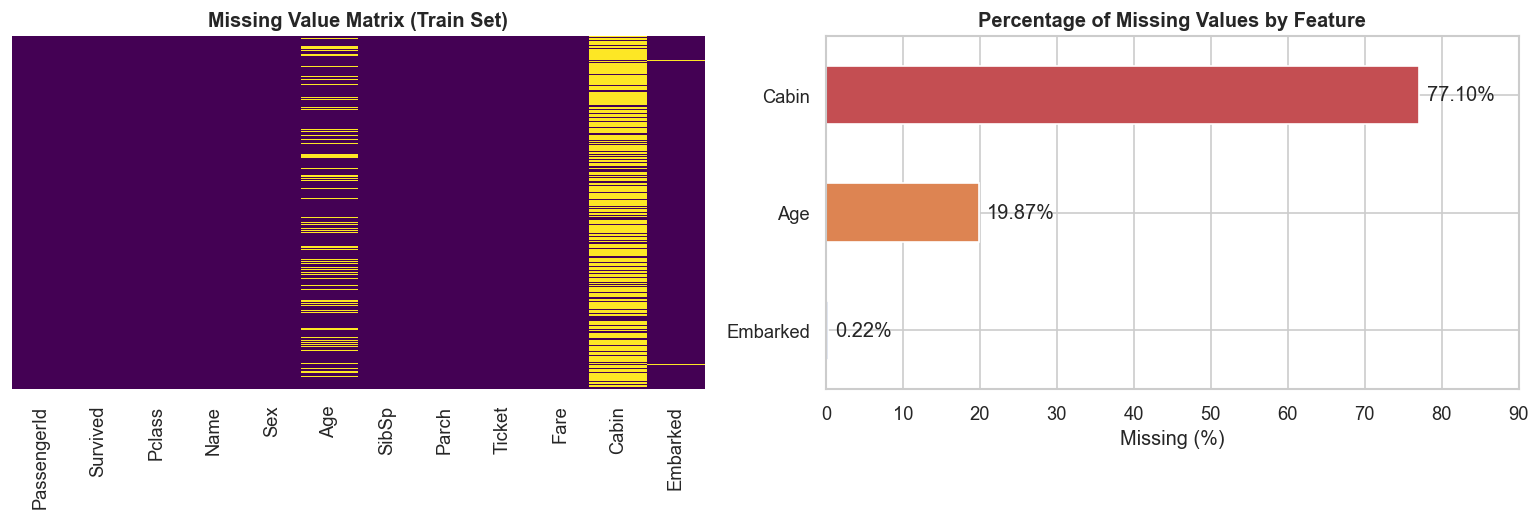

In [3]:
# Visualize missing data patterns across features
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(train_df.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[0])
axes[0].set_title('Missing Value Matrix (Train Set)')

missing_pct = (train_df.isnull().mean() * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=True)
missing_pct.plot(kind='barh', color=['#4c72b0', '#dd8452', '#c44e52'], ax=axes[1])
axes[1].set_title('Percentage of Missing Values by Feature')
axes[1].set_xlabel('Missing (%)')
for idx, val in enumerate(missing_pct):
    axes[1].text(val + 1, idx, f'{val:.2f}%', va='center')
axes[1].set_xlim(0, 90)

plt.tight_layout()
plt.show()

## 3. Data Cleaning & Type Conversion

Key cleaning decisions based on the missing-value audit:
1. **`Age` (19.87% missing):** Impute using the median age grouped by `Pclass` and `Sex` to preserve demographic differences rather than distorting the distribution with a single global mean/median.
2. **`Embarked` (0.22% missing):** Fill the 2 missing entries with the mode (`'S'`, Southampton).
3. **`Cabin` (77.10% missing):** Too sparse for direct imputation; extract a binary indicator `Has_Cabin` (`1` if recorded, `0` if missing) plus `Deck` (`'U'` for Unknown).
4. **`Fare` (1 missing in test):** Impute using median fare of the corresponding `Pclass`.
5. **Feature Engineering & Type Casting:** Create `FamilySize` (`SibSp + Parch + 1`), `IsAlone`, `AgeGroup`, and cast `Pclass`, `Sex`, `Embarked`, and `Survived` to appropriate types.

In [4]:
df = train_df.copy()

# 1. Impute Age using median grouped by Pclass and Sex
df['Age'] = df['Age'].fillna(df.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

# 2. Impute Embarked with mode ('S')
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# 3. Extract Cabin availability and Deck letter instead of dropping all information
df['Has_Cabin'] = df['Cabin'].notnull().astype(int)
df['Deck'] = df['Cabin'].str[0].fillna('U')

# 4. Feature engineering for family structure & age brackets
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child (0-12)', 'Teen (13-18)', 'Young Adult (19-35)', 'Adult (36-60)', 'Senior (60+)']
)

# 5. Convert appropriate columns to categorical dtype
df['Sex'] = df['Sex'].astype('category')
df['Embarked'] = df['Embarked'].astype('category')
df['Pclass_Cat'] = df['Pclass'].map({1: '1st Class', 2: '2nd Class', 3: '3rd Class'}).astype('category')

print('Remaining missing values in cleaned dataset:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nUpdated Data Types:')
print(df[['Survived', 'Pclass', 'Pclass_Cat', 'Sex', 'Age', 'AgeGroup', 'Fare', 'Embarked', 'Has_Cabin', 'FamilySize']].dtypes)

Remaining missing values in cleaned dataset:
Cabin    687
dtype: int64

Updated Data Types:
Survived         int64
Pclass           int64
Pclass_Cat    category
Sex           category
Age            float64
AgeGroup      category
Fare           float64
Embarked      category
Has_Cabin        int32
FamilySize       int64
dtype: object


## 4. Summary Statistics & Group-Based Insights

In [5]:
# Numerical summary statistics
display(df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Has_Cabin']].describe().round(2))

# Categorical summary statistics
display(df.describe(include=['object', 'category']))

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,Has_Cabin
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,0.38,2.31,29.11,0.52,0.38,32.20,1.90,0.23
std,0.49,0.84,13.30,1.10,0.81,49.69,1.61,0.42
min,0.00,1.00,0.42,0.00,0.00,0.00,1.00,0.00
25%,0.00,2.00,21.50,0.00,0.00,7.91,1.00,0.00
50%,0.00,3.00,26.00,0.00,0.00,14.45,1.00,0.00
75%,1.00,3.00,36.00,1.00,0.00,31.00,2.00,0.00
max,1.00,3.00,80.00,8.00,6.00,512.33,11.00,1.00


,Name,Sex,Ticket,Cabin,Embarked,Deck,AgeGroup,Pclass_Cat
count,891,891,891,204,891,891,891,891
unique,891,2,681,147,3,9,5,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S,U,Young Adult (19-35),3rd Class
freq,1,577,7,4,646,687,514,491


In [6]:
# Overall survival rate
overall_survival = df['Survived'].mean() * 100
print(f'Overall Survival Rate: {overall_survival:.2f}% ({df["Survived"].sum()}/{len(df)} passengers)\n')

# Survival by Sex
print('--- Survival Rate by Gender ---')
display(df.groupby('Sex', observed=False)['Survived'].agg(Count='count', Survived='sum', Survival_Rate=lambda x: round(x.mean()*100, 2)))

# Survival by Passenger Class
print('--- Survival Rate by Passenger Class ---')
display(df.groupby('Pclass_Cat', observed=False)['Survived'].agg(Count='count', Survived='sum', Survival_Rate=lambda x: round(x.mean()*100, 2)))

# Cross-tabulation: Survival Rate (%) by Class and Gender
print('--- Survival Rate (%) by Class & Gender ---')
pclass_sex_pivot = (df.pivot_table(index='Pclass_Cat', columns='Sex', values='Survived', aggfunc='mean', observed=False) * 100).round(2)
display(pclass_sex_pivot)

# Survival by Embarked Port and Cabin Status
print('--- Survival Rate by Embarkation Port ---')
display(df.groupby('Embarked', observed=False)['Survived'].agg(Count='count', Survived='sum', Survival_Rate=lambda x: round(x.mean()*100, 2)))

print('--- Survival Rate by Age Group ---')
display(df.groupby('AgeGroup', observed=False)['Survived'].agg(Count='count', Survived='sum', Survival_Rate=lambda x: round(x.mean()*100, 2)))

Overall Survival Rate: 38.38% (342/891 passengers)

--- Survival Rate by Gender ---


,Count,Survived,Survival_Rate
Sex,,,
female,314,233,74.20
male,577,109,18.89


--- Survival Rate by Passenger Class ---


,Count,Survived,Survival_Rate
Pclass_Cat,,,
1st Class,216,136,62.96
2nd Class,184,87,47.28
3rd Class,491,119,24.24


--- Survival Rate (%) by Class & Gender ---


Sex,female,male
Pclass_Cat,,
1st Class,96.81,36.89
2nd Class,92.11,15.74
3rd Class,50.00,13.54


--- Survival Rate by Embarkation Port ---


,Count,Survived,Survival_Rate
Embarked,,,
C,168,93,55.36
Q,77,30,38.96
S,646,219,33.90


--- Survival Rate by Age Group ---


,Count,Survived,Survival_Rate
AgeGroup,,,
Child (0-12),69,40,57.97
Teen (13-18),70,30,42.86
Young Adult (19-35),514,184,35.80
Adult (36-60),216,83,38.43
Senior (60+),22,5,22.73


## 5. Data Visualizations: Distributions, Survival Bar Plots & Correlation Heatmaps

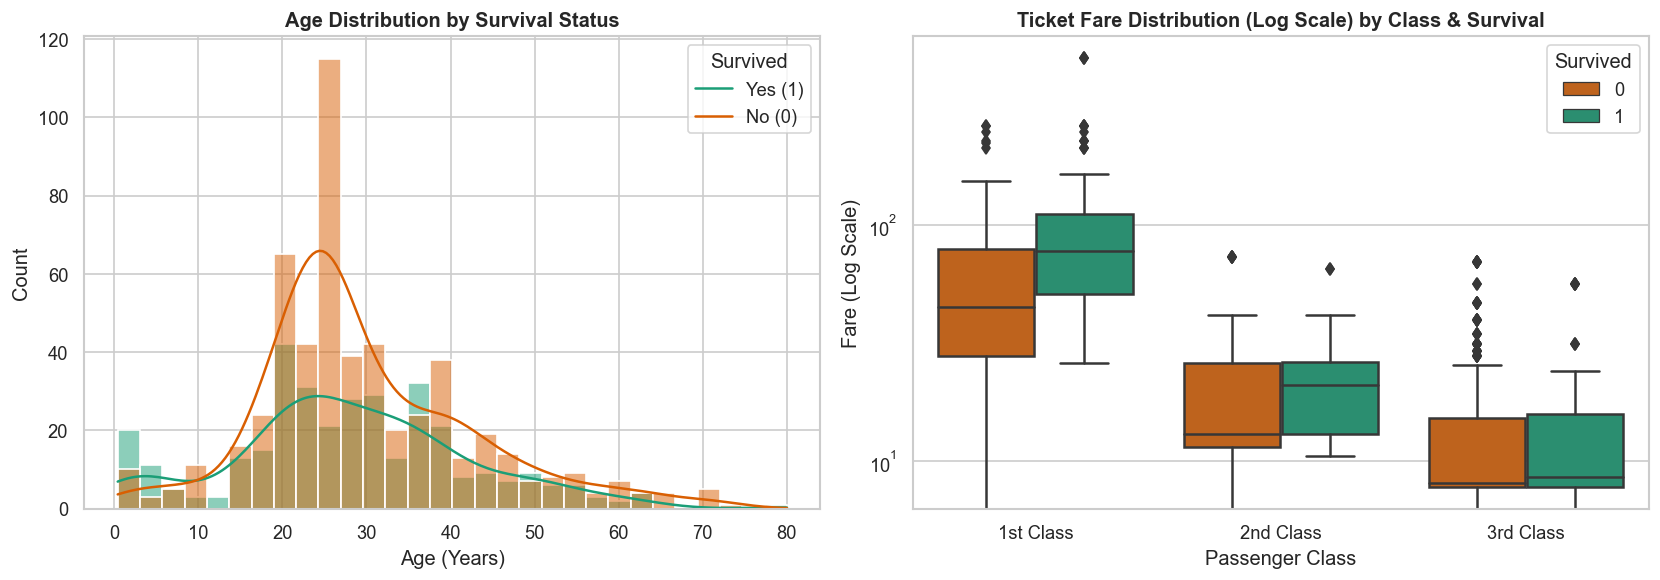

In [7]:
# 5.1 Distributions of Age and Fare by Survival Status
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, palette={0: '#d95f02', 1: '#1b9e77'}, ax=axes[0])
axes[0].set_title('Age Distribution by Survival Status')
axes[0].set_xlabel('Age (Years)')
axes[0].legend(title='Survived', labels=['Yes (1)', 'No (0)'])

sns.boxplot(data=df, x='Pclass_Cat', y='Fare', hue='Survived', palette={0: '#d95f02', 1: '#1b9e77'}, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Ticket Fare Distribution (Log Scale) by Class & Survival')
axes[1].set_xlabel('Passenger Class')
axes[1].set_ylabel('Fare (Log Scale)')

plt.tight_layout()
plt.show()

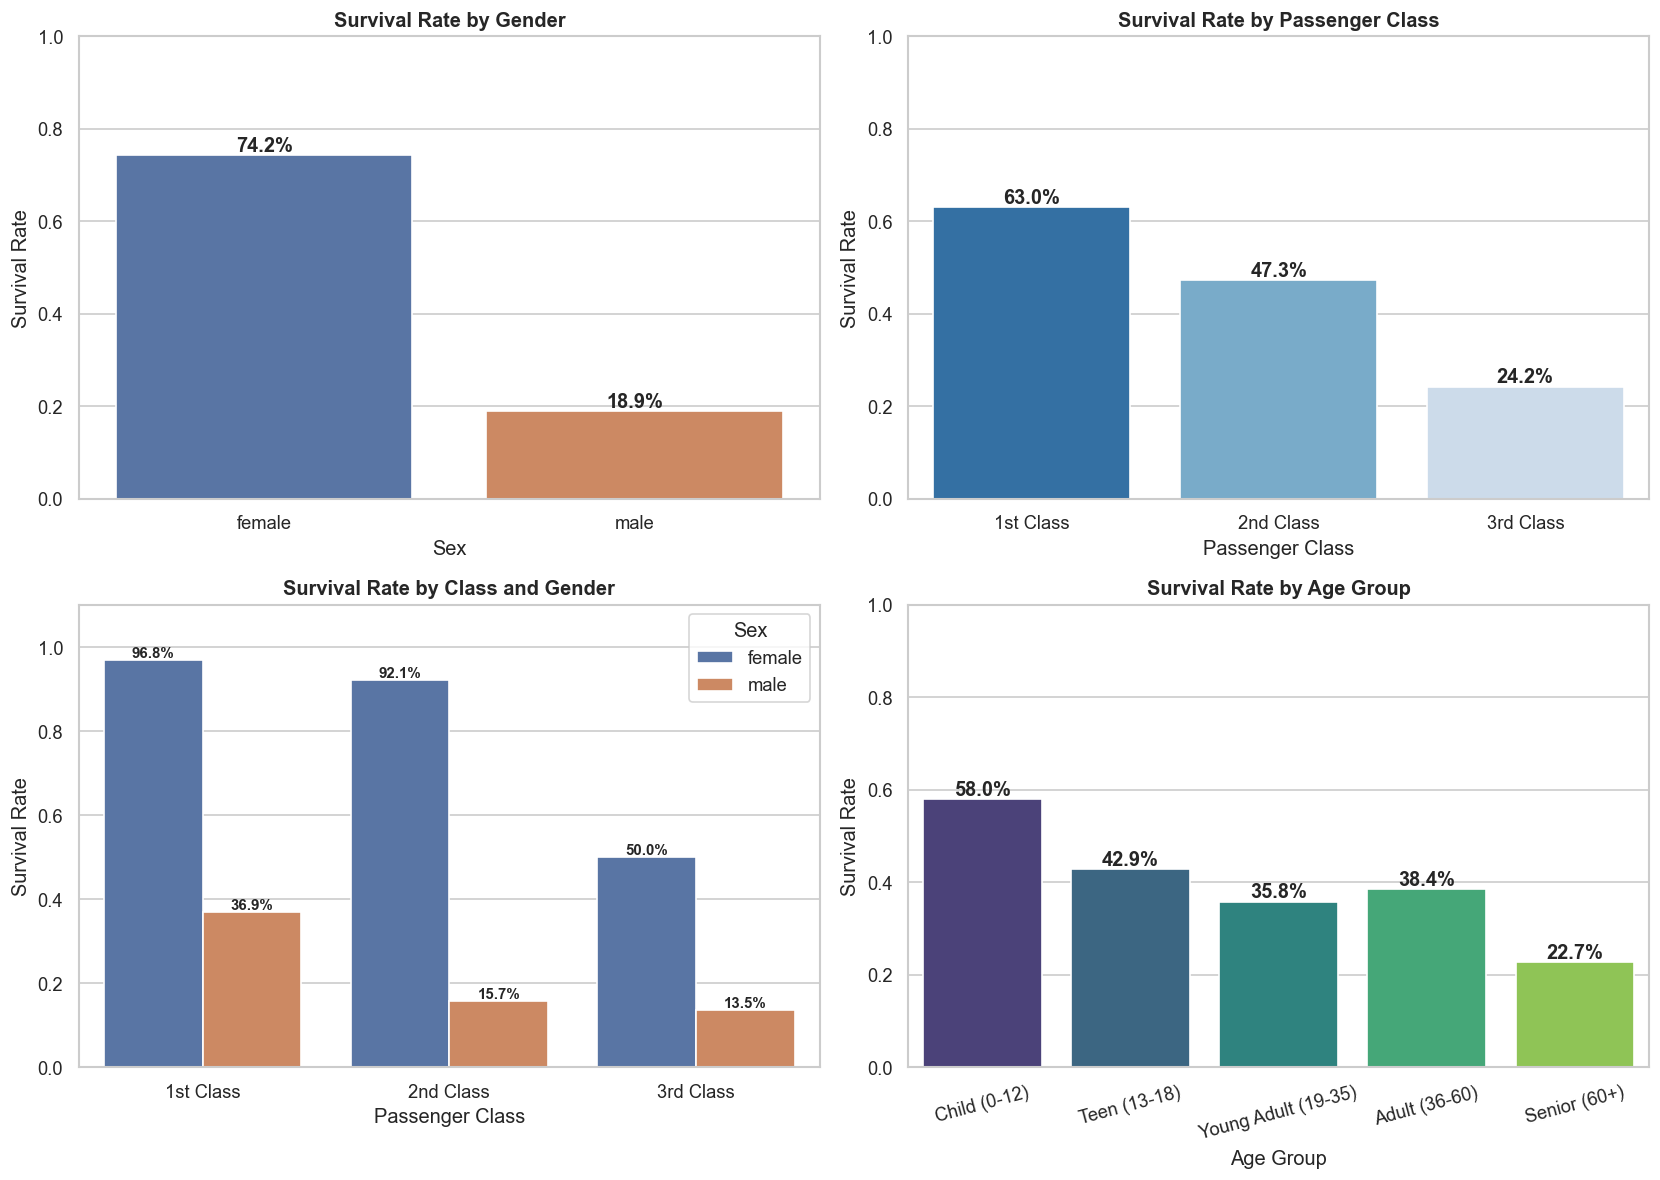

In [8]:
# 5.2 Bonus: Bar Plots of Survival Rates Across Key Dimensions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot A: Survival Rate by Sex
ax = sns.barplot(data=df, x='Sex', y='Survived', palette=['#4c72b0', '#dd8452'], errorbar=None, ax=axes[0, 0])
axes[0, 0].set_title('Survival Rate by Gender')
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_ylabel('Survival Rate')
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontweight='bold')

# Plot B: Survival Rate by Passenger Class
ax = sns.barplot(data=df, x='Pclass_Cat', y='Survived', palette='Blues_r', errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title('Survival Rate by Passenger Class')
axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_xlabel('Passenger Class')
axes[0, 1].set_ylabel('Survival Rate')
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontweight='bold')

# Plot C: Grouped Bar Plot - Survival Rate by Class & Gender
ax = sns.barplot(data=df, x='Pclass_Cat', y='Survived', hue='Sex', palette=['#4c72b0', '#dd8452'], errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title('Survival Rate by Class and Gender')
axes[1, 0].set_ylim(0, 1.1)
axes[1, 0].set_xlabel('Passenger Class')
axes[1, 0].set_ylabel('Survival Rate')
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot D: Survival Rate by Age Group
ax = sns.barplot(data=df, x='AgeGroup', y='Survived', palette='viridis', errorbar=None, ax=axes[1, 1])
axes[1, 1].set_title('Survival Rate by Age Group')
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_xlabel('Age Group')
axes[1, 1].set_ylabel('Survival Rate')
axes[1, 1].tick_params(axis='x', rotation=15)
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

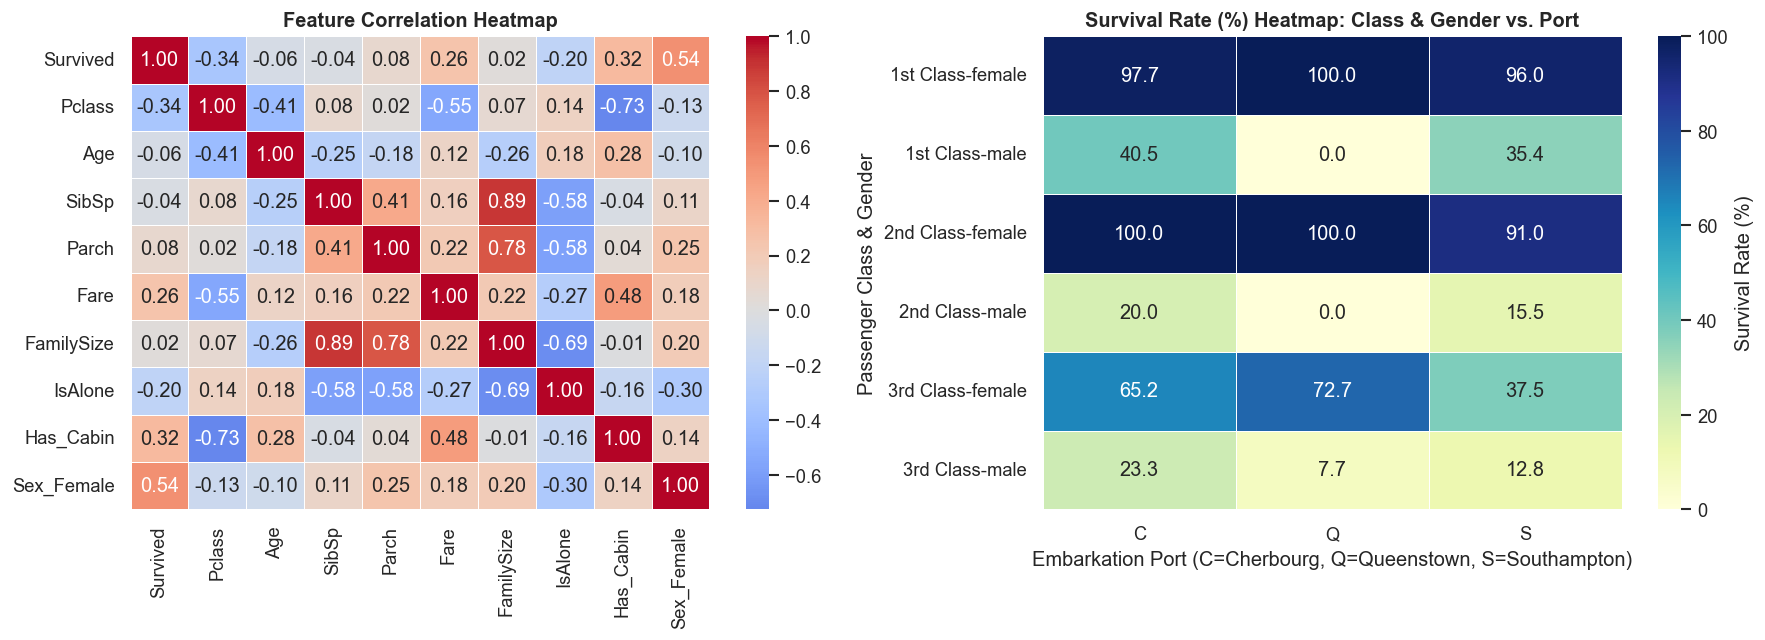

In [9]:
# 5.3 Bonus: Heatmaps (Feature Correlations & Multi-Dimensional Survival Rates)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Heatmap 1: Numerical Feature Correlation Matrix
corr_df = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Has_Cabin']].copy()
corr_df['Sex_Female'] = (df['Sex'] == 'female').astype(int)
corr_matrix = corr_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5, ax=axes[0])
axes[0].set_title('Feature Correlation Heatmap')

# Heatmap 2: Survival Rate (%) Pivot Heatmap (Pclass x Embarked vs Sex)
survival_heatmap_data = df.pivot_table(
    index=['Pclass_Cat', 'Sex'],
    columns='Embarked',
    values='Survived',
    aggfunc='mean',
    observed=False
) * 100

sns.heatmap(survival_heatmap_data, annot=True, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=100, linewidths=0.5, cbar_kws={'label': 'Survival Rate (%)'}, ax=axes[1])
axes[1].set_title('Survival Rate (%) Heatmap: Class & Gender vs. Port')
axes[1].set_xlabel('Embarkation Port (C=Cherbourg, Q=Queenstown, S=Southampton)')
axes[1].set_ylabel('Passenger Class & Gender')

plt.tight_layout()
plt.show()

## 6. Key Findings Summary

- **Overall Survival:** Only **38.38%** (342 out of 891) of passengers in the training dataset survived.
- **Gender Impact (`Women and Children First`):** Females survived at **74.20%** compared to **18.89%** for males — the single strongest predictor of survival ($r = 0.54$).
- **Socioeconomic Class (`Pclass`):** 1st-class passengers had a **62.96%** survival rate, compared to **47.28%** in 2nd class and **24.24%** in 3rd class. Nearly all 1st-class women survived (**96.81%**), whereas only **13.54%** of 3rd-class men survived.
- **Age & Cabin:** Children (ages 0–12) had the highest survival rate among age brackets (**57.97%**), and passengers with recorded cabins (`Has_Cabin = 1`) survived at much higher rates than those without.